# [CS303] Practice 4 - Cost-Based and Informed Search

## 1. Requirements

In Practice 3, **BFS** and **DFS** ignored edge weights. In this practice, you will use path costs and heuristic information.

1. Implement **Uniform-Cost Search (UCS)** using `g(n)`.
2. Implement **Greedy Best-First Search (GBFS)** using `h(n)`.
3. Implement **A*** using `f(n) = g(n) + h(n)`.
4. Preserve the alphabetical tie-break rule and the correct stop condition.
5. Use Python generators (`yield`) to expose each search step.
6. Compare solution cost and search effort on the same graphs.

| Algorithm | Priority | Optimal with the assumptions in this practice? |
|---|---|---|
| **UCS** | `g(n)` | Yes, because every edge cost is positive |
| **GBFS** | `h(n)` | No |
| **A\*** | `g(n) + h(n)` | Yes when `h` is admissible and states can be improved/reopened |

#### Required rules

- **Goal test:** stop only when the goal is **popped** from the priority queue.
- **Tie-break:** for equal priority, pop the alphabetically smaller node.
- **Relaxation:** UCS and A* must replace a state's parent and `g` value when a cheaper route is found.
- **Stale entries:** because `heapq` has no decrease-key operation, ignore an entry whose stored `g` is no longer the best known value.
- **Snapshot contract:** yield one snapshot after every real node expansion, including the goal expansion.

#### **Practice Deadline and Checking Policy**

The score for this practice is determined by **when you have your work checked during your lab session**. Please follow the schedule of your own lab group.

| Lab Group     | Full Credit (100%)           | Late Check (50%)        | After the 50% Deadline |
| ------------- | ---------------------------- | ----------------------- | ---------------------- |
| **Wednesday** | before or on **Oct. 14**     | **Oct. 21**             | 0%                     |
| **Thursday**  | **Oct. 8** or  **Oct. 15**   | **Oct. 22**             | 0%                     |
| **Friday**    | **Oct. 9** or  **Oct. 16**   | **Oct. 23**             | 0%                     |

You have **two lab sessions to complete and have your work checked for full credit (100%)**. If you miss both sessions, you can still have your work checked at the designated late-check session, but you will receive only **50% of the points**. Any check after the 50% deadline will receive **0 points**.

**Holiday schedule adjustment:** The **Wednesday group has one more chance of Full Credit than the Thursday and Friday groups**. 

**Important:** The score is determined by the **date of your in-person check**.

#### **What will be checked**

- You understand every line of your code.
- Your program runs without errors.
- Expansion order, returned path, and total cost are correct.
- Your implementation handles improved paths and stale heap entries.
- You can explain why GBFS and A* behave differently.



## 2. Graph Data and Heuristics

The graph format extends Practice 3 with one extra line:

1. Node names: first token is the start, last token is the goal;
2. Number of directed edges;
3. `u v weight` for every edge;
4. Drawing positions: `x1 y1 x2 y2 ...`;
5. Heuristic values: one `h(n)` value per node, in node-list order.

The heuristic estimates the remaining cost to the goal. Both supplied heuristic tables are admissible. Case 1 deliberately assigns low values to dead-end nodes, showing that admissible does not necessarily mean highly informative.


In [34]:
import heapq
import math
import time
from collections.abc import Callable, Generator
from typing import TypeAlias

import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import clear_output

# Type aliases make the function signatures easier to read.
# A graph maps each node name to a list of (child, edge_cost) pairs.
Graph: TypeAlias = dict[str, list[tuple[str, int]]]
PositionMap: TypeAlias = dict[str, tuple[float, float]]
Heuristic: TypeAlias = dict[str, float]
ParentMap: TypeAlias = dict[str, str | None]
PathCost: TypeAlias = dict[str, float]
SearchSnapshot: TypeAlias = dict[str, object]
SearchGenerator: TypeAlias = Generator[SearchSnapshot, None, None]

# Case 1: GBFS is misled and returns a suboptimal path.
CASE1 = """S A B C D E F G H
13
S A 3
A D 3
S B 6
S C 2
B D 4
B G 9
B E 2
D F 5
E F 6
E H 5
F G 5
H G 8
C E 1
-1 0 0 1 0 0 0 -1 1 1 1 -1 1.8 1 2.5 0 1.8 -1
8 0 1 6 0 5 0 0 0
"""

# Case 2: a Romanian-road-style graph with straight-line estimates to B.
CASE2 = """A T Z O L D S R C F P B
15
A Z 75
A S 140
A T 118
T L 70
Z O 71
O S 151
L D 145
D C 120
S R 80
S F 99
R P 97
R C 146
C P 138
F B 211
P B 101
-1.9 0.9 -1.9 -0.3 -1.8 1.5 -1.6 2.1 -1 -0.7 -0.9 -1.6 -0.7 0.6 -0.4 -0.2 0 -1.8 0.6 0.3 0.75 -0.8 2 -1.5
366 329 374 380 244 242 253 193 160 176 100 0
"""

def load_graph(text: str) -> tuple[Graph, str, str, PositionMap, Heuristic]:
    """Parse one embedded test case and return its five components."""
    lines = text.strip().splitlines()
    nodes = lines[0].split()
    edge_count = int(lines[1])
    graph: Graph = {node: [] for node in nodes}
    for i in range(edge_count):
        u, v, weight = lines[2 + i].split()
        graph[u].append((v, int(weight)))
    pos_values = [float(x) for x in lines[2 + edge_count].split()]
    positions: PositionMap = {
        node: (pos_values[2*i], pos_values[2*i+1])
        for i, node in enumerate(nodes)
    }
    h_values = [float(x) for x in lines[3 + edge_count].split()]
    if len(h_values) != len(nodes):
        raise ValueError("There must be exactly one heuristic value per node.")
    heuristic: Heuristic = dict(zip(nodes, h_values))
    return graph, nodes[0], nodes[-1], positions, heuristic

G1, start1, goal1, pos1, h1 = load_graph(CASE1)
G2, start2, goal2, pos2, h2 = load_graph(CASE2)
print(f"Case 1: {start1} -> {goal1}; h(start)={h1[start1]}")
print(f"Case 2: {start2} -> {goal2}; h(start)={h2[start2]}")


Case 1: S -> H; h(start)=8.0
Case 2: A -> B; h(start)=366.0


## 3. Given Helper Functions

`make_snapshot` defines the generator interface. Do not change its keys.

Each yielded dictionary contains:

- `frontier`: nodes currently waiting, sorted by queue priority and then alphabetically;
- `expanded`: the expansion order so far;
- `current`: the node expanded in this step;
- `path_cost`: path cost discovered for every reached state;
- `parent`: predecessor links used to reconstruct a path;
- `done`, `path`, and `cost`: final-result fields.

`reconstruct_path` is also given. Your algorithms should update `parent` whenever they discover a cheaper route.


In [35]:
def reconstruct_path(parent: ParentMap, goal: str) -> list[str]:
    """Follow parent links backward from the goal, then reverse the result."""
    path = []
    node = goal
    while node is not None:
        path.append(node)
        node = parent[node]
    return path[::-1]

def ordered_frontier(heap: list[tuple]) -> list[str]:
    """Return unique node names in heap priority order."""
    result, seen = [], set()
    for entry in sorted(heap):
        node = entry[1]
        if node not in seen:
            result.append(node)
            seen.add(node)
    return result

def make_snapshot(
    heap: list[tuple],
    expanded: list[str],
    current: str,
    path_cost: PathCost,
    parent: ParentMap,
    done: bool = False,
) -> SearchSnapshot:
    """Copy the current search state for animation and result checking."""
    path = reconstruct_path(parent, current) if done else None
    return {
        "frontier": ordered_frontier(heap),
        "expanded": list(expanded),
        "current": current,
        "path_cost": dict(path_cost),
        "parent": dict(parent),
        "done": done,
        "path": path,
        "cost": path_cost[current] if done else None,
    }


## 4. Python `heapq` Crash Course

A **priority queue** removes the item with the smallest priority, rather than the item inserted first or last. Python implements a min-priority queue with the `heapq` module.

The heap is stored in an ordinary list:

```python
frontier = []
heapq.heappush(frontier, item)   # insert one item
item = heapq.heappop(frontier)  # remove and return the smallest item
```

Do not use `frontier.append(...)` or `frontier.pop(0)` for these algorithms. Those operations do not maintain heap order.


In [36]:
# Smallest number is removed first, regardless of insertion order.
number_heap: list[int] = []
heapq.heappush(number_heap, 8)
heapq.heappush(number_heap, 3)
heapq.heappush(number_heap, 5)
# after pushing 8, 3, 5, the internal list representation of the heap turns to [3, 8, 5] automatically

print("Internal list:", number_heap)  # A heap is not a fully sorted list.
print("First pop:", heapq.heappop(number_heap))
print("Second pop:", heapq.heappop(number_heap))
# output: Internal list: [3, 8, 5], First pop: 3, Second pop: 5


Internal list: [3, 8, 5]
First pop: 3
Second pop: 5


### 4.1 Tuples provide a priority and a tie-break

`heapq` compares tuples from left to right:

1. Compare the first values (the priorities).
2. If they tie, compare the second values.
3. Continue only if another tie remains.

Putting the node name second automatically gives the required alphabetical tie-break.


In [37]:
frontier: list[tuple[int, str]] = []
heapq.heappush(frontier, (5, "C"))
heapq.heappush(frontier, (2, "B"))
heapq.heappush(frontier, (2, "A"))

while frontier:
    priority, node = heapq.heappop(frontier)
    print(priority, node)

# first compare the first element of the tuple, which is the priority.
# if first element is equal, then compare the second element, which is the node alphabet

# 2 = 2, so A comes before B because "A" < "B" in lexicographical order.
# 2 < 5, so C comes last.
# so output: (2, A), then (2, B), then (5, C).


2 A
2 B
5 C


### 4.2 Heap entries used in this practice

- UCS uses `(path_cost, node)`.
- GBFS uses `(heuristic[node], node)`. Its `path_cost` dictionary is only for reporting the final solution cost.
- A* uses `(path_cost + heuristic, node, path_cost_at_insertion)`.

The third A* value lets us recognize stale entries.

### 4.3 Why stale entries exist

`heapq` has no direct decrease-key operation. Suppose a node is first reached with path cost 10 and later with cost 7. Both entries may remain in the heap. When the old entry is popped, compare its stored cost with `path_cost[node]`. If they differ, use `continue` to skip it.

Only UCS and A* need this relaxation/stale-entry mechanism. This exercise's GBFS marks nodes when generated and never tries to improve their path costs.


## 5. TODO - Uniform-Cost Search

UCS expands the node with the smallest path cost from the start. 

Do not stop when the goal is generated: another frontier node may still lead to a cheaper goal path.


In [38]:
def UCS(
    Graph: Graph,
    start: str,
    goal: str,
    heuristic: Heuristic | None = None,
) -> SearchGenerator:
    """Generate snapshots of Uniform-Cost Search (priority = path cost)."""
    # Each heap entry is (priority, node). For UCS, priority equals path cost.
    heap: list[tuple[float, str]] = [(0, start)]
    path_cost: PathCost = {start: 0}
    parent: ParentMap = {start: None}
    expanded: list[str] = []

    while heap:
        # heappop removes the tuple with the smallest first value.
        # If priorities tie, Python compares the node names alphabetically.
        g, node = heapq.heappop(heap)

        # The same node may have multiple entries in the heap.
        # TODO 1: Skip this entry if a cheaper path to the node
        # has already been found (g != path_cost[node]).

        if g != path_cost[node]:
            continue
        # path_cost stores the cheapest path cost to each node found so far.
        # so if current node's cost is greater than the recorded one,
        # it means that this entry is outdated!!!
        # we should skip it cuz it can't lead to the optimal solution.

        # if not skipped, this node is assured to be the latest and cheapest one
        # This entry is up to date, so now we can expand the node.
        expanded.append(node)

        # if the current node is the goal, we can stop searching and return the result.
        if node == goal:
            # yield a snapshot, with [ done=True ] to indicate that the search is complete
            yield make_snapshot(heap, expanded, node, path_cost, parent, done=True)
            return

        # TODO 2: Relax outgoing edges in alphabetical order.
        # For every (child, step_cost):
        #   new_cost = path_cost[node] + step_cost
        # If new_cost is smaller than the recorded cost, update path_cost,
        # update parent, and push (new_cost, child) into the heap.

        # edge relaxation:
        # update path cost and parent for each child if a cheaper path is found

        # Graph[node] is a list of (child, step_cost) pairs. We sort it to ensure alphabetical order.
        # it returns all children of the current node in alphabetical order, along with their step costs.
        for child, step_cost in sorted(Graph[node]):

            # reaching child = reaching parent + parent -> child
            new_cost = path_cost[node] + step_cost

            # let's discuss:
            # 1. if child never been reached before, old_cost = infinity
            # so new_cost must be recorded, as it must < infinity
            # 2. if child has been reached before, old_cost = path_cost[child]
            old_cost = path_cost.get(child, math.inf)

            # relaxation condition satisfied:
            # if new cost is even smaller than the recorded cost (recent optimal)
            if new_cost < old_cost:

                # update optimal path cost to reach child
                path_cost[child] = new_cost

                # update child's parent, so finally we can reconstruct the optimal path via this parent link
                parent[child] = node

                # note that we don't remove the old entry from the heap,
                # we just add a new entry with the updated cost.
                # the old entry will be skipped when it is popped from the heap,
                # because its cost will not match the current optimal cost in path_cost.
                heapq.heappush(heap, (new_cost, child))
                # what we actually store in the heap is 'state', or we say, a snapshot.
                # one node can have multiple states stored inside the heap,
                # and we only care about the state with the lowest cost, which is the optimal one.

        # invoke a given method to better visualize the current state of the search algorithm
        yield make_snapshot(heap, expanded, node, path_cost, parent)


## 6. TODO - Greedy Best-First Search

GBFS chooses the smallest heuristic value and ignores the path cost already paid. For this exercise, mark a state discovered when it is enqueued, as in Practice 3.

GBFS may expand fewer nodes, but it is not optimal.


In [39]:
def GBFS(
    Graph: Graph,
    start: str,
    goal: str,
    heuristic: Heuristic,
) -> SearchGenerator:
    """Generate snapshots of GBFS (priority = heuristic only)."""
    # GBFS deliberately stores only (h, node) in its heap.
    # path_cost is recorded for reporting the final solution, not for selection.
    heap: list[tuple[float, str]] = [(heuristic[start], start)]
    discovered: set[str] = {start}
    path_cost: PathCost = {start: 0}
    parent: ParentMap = {start: None}
    expanded: list[str] = []

    while heap:
        h_value, node = heapq.heappop(heap)
        expanded.append(node)

        if node == goal:
            yield make_snapshot(heap, expanded, node, path_cost, parent, done=True)
            return

        # TODO: Add undiscovered children in alphabetical order.
        # Record parent[child] and path_cost[child] for the result.
        # Push only (heuristic[child], child) into the heap.

        # Graph returns all children of the current node in alphabetical order, along with their step costs.
        for child, step_cost in sorted(Graph[node]):

            # not discovered yet -> explore it and mark it as discovered
            if child not in discovered:
                    
                    # tag the child as 'discovered' to prevent it from being added to the heap multiple times.
                    discovered.add(child)
        
                    # again record the path cost and parent for each child, even though GBFS doesn't use them for selection.
                    path_cost[child] = path_cost[node] + step_cost
                    parent[child] = node
        
                    # for GBFS (greedy best-first search):
                    # note that the priority of the heap is 'heuristic',
                    # with path cost not being considered at all
                    # heuristic[child] is the straight-line estimate from child to the goal (an admissible one)
                    heapq.heappush(heap, (heuristic[child], child))

        # invoke visualizer to show the current state of the search algorithm
        yield make_snapshot(heap, expanded, node, path_cost, parent)


## 7. TODO - A* Search

A* combines actual cost and estimated remaining cost. Its relaxation logic is the same as UCS; only the heap priority changes.

This implementation permits a cheaper route to update a previously reached state. That behavior is important when a heuristic is admissible but inconsistent.


In [40]:
def ASTAR(
    Graph: Graph,
    start: str,
    goal: str,
    heuristic: Heuristic,
) -> SearchGenerator:
    """Generate snapshots of A* Search (priority = path cost + heuristic)."""
    # Each entry is (f, node, path_cost_at_insertion).
    heap: list[tuple[float, str, float]] = [(heuristic[start], start, 0)]
    path_cost: PathCost = {start: 0}
    parent: ParentMap = {start: None}
    expanded: list[str] = []

    while heap:
        f, node, g = heapq.heappop(heap)

        # The same node may have multiple entries in the heap.
        # TODO 1: Skip this entry if a cheaper path to the node
        # has already been found (g != path_cost[node]).

        if g != path_cost[node]:
            continue

        # This entry is up to date, so now we can expand the node.
        expanded.append(node)
        if node == goal:
            yield make_snapshot(heap, expanded, node, path_cost, parent, done=True)
            return

        # TODO 2: Relax outgoing edges in alphabetical order.
        # If a cheaper child path is found, update path_cost and parent,
        # then push (new_cost + heuristic[child], child, new_cost).

        for child, step_cost in sorted(Graph[node]):

            # calculate the g value (start -> node -> child)
            # g value = cost to reach child by passing through the current node
            new_cost = path_cost[node] + step_cost

            old_cost = path_cost.get(child, math.inf)

            # edge relaxation:
            if new_cost < old_cost:
                path_cost[child] = new_cost
                parent[child] = node

                # for A* algorithm, the priority of the heap is f = g + h
                # this is the only difference between A* and UCS, which only uses g as the priority
                # this means that A* takes into account both the cost to reach the node and the estimated cost to reach the goal from that node.
                # also, the heap will always pop the node with the lowest f value each time
                heapq.heappush(heap, (new_cost + heuristic[child], child, new_cost))
                # note that all the heuristic values are already precomputed and stored
                # also note that we record g value (path cost) so that we can skip outdated entries in the heap, just like UCS.

        yield make_snapshot(heap, expanded, node, path_cost, parent)


## 8. Animation and Result Driver (given)

### Node color legend

| Color | Meaning |
|---|---|
| **White** | Undiscovered: the node has not entered the frontier |
| **Brown** | Frontier: the node has been discovered and is waiting to be expanded |
| **Light gray** | Expanded: the node has already been removed from the frontier and processed |
| **Red** | Current: the node expanded in the current animation frame |
| **Light green** | Final path: the node belongs to the returned solution path |

The current node is also part of the expanded list, but it is shown in **red** so that the latest step is easy to see. In the final frame, solution-path nodes are shown in **light green**, except that the current goal node remains red because the current-node color has higher display priority.

Each node label also shows `h`, its heuristic estimate to the goal. Edge labels show the actual step costs.


In [41]:
WHITE, BROWN, GRAY, RED, GREEN = "white", "saddlebrown", "lightgray", "tomato", "palegreen"

def draw_frame(
    Graph: Graph,
    position: PositionMap,
    heuristic: Heuristic,
    snapshot: SearchSnapshot,
) -> None:
    """Draw one snapshot produced by a search generator."""
    graph = nx.DiGraph()
    for u in Graph:
        for v, w in Graph[u]:
            graph.add_edge(u, v, weight=w)
    frontier = set(snapshot["frontier"])
    expanded = set(snapshot["expanded"])
    current = snapshot["current"]
    path = set(snapshot["path"] or [])
    colors = []
    for node in graph.nodes:
        if node == current:
            colors.append(RED)
        elif node in path:
            colors.append(GREEN)
        elif node in frontier:
            colors.append(BROWN)
        elif node in expanded:
            colors.append(GRAY)
        else:
            colors.append(WHITE)
    labels = {node: f"{node}\nh={heuristic[node]:g}" for node in graph.nodes}
    edge_labels = {(u, v): w for u in Graph for v, w in Graph[u]}
    plt.figure(figsize=(7.5, 4.5))
    nx.draw(graph, position, labels=labels, with_labels=True, node_color=colors,
            node_size=1050, edge_color="gray", font_weight="bold")
    nx.draw_networkx_edge_labels(graph, position, edge_labels=edge_labels)
    plt.axis("off")
    plt.show()
    plt.close()

def run_search(
    algorithm: Callable[[Graph, str, str, Heuristic], SearchGenerator],
    text: str,
    label: str,
    animate: bool = False,
    delay: float = 0.5,
    step: bool = False,
) -> SearchSnapshot | None:
    """Run a search, optionally pausing for input after each frame."""
    Graph, start, goal, position, heuristic = load_graph(text)
    generator = algorithm(Graph, start, goal, heuristic)
    last: SearchSnapshot | None = None
    stopped_by_user = False
    for frame_no, snapshot in enumerate(generator, start=1):
        last = snapshot
        if animate:
            clear_output(wait=True)
            print(f"--- {label} | {start} -> {goal} | frame {frame_no:02d} ---")
            print("current:", snapshot["current"], "frontier:", snapshot["frontier"])
            draw_frame(Graph, position, heuristic, snapshot)
            if step:
                # This intentionally matches the Practice 3 interaction style.
                answer = input("Press Enter for the next frame (q + Enter to stop) >> ")
                if answer.strip().lower() == "q":
                    stopped_by_user = True
                    break
            elif delay:
                time.sleep(delay)
    if stopped_by_user:
        print("Search stopped by the user.")
        return last
    if last is None or not last["done"]:
        print("No solution found.")
        return last
    print("expansion order:", last["expanded"])
    print("path:", last["path"])
    print("total cost:", last["cost"])
    return last


## 9. Run the Algorithms

First use `animate=False` for quick debugging. It runs to completion and returns the final snapshot.

For automatic animation, use `animate=True, step=False`. For manual stepping, use `animate=True, step=True`.

- Press **Enter** to display the next search frame.
- Type **q** and press Enter to stop.

This deliberately uses the same `input()` interaction as Practice 3. In classic Jupyter Notebook, the input field normally appears below the current output. In VS Code, it may instead appear near the top of the window.


In [42]:
# Uncomment after completing the TODOs.
ucs1 = run_search(UCS, CASE1, "UCS CASE1")
gbfs1 = run_search(GBFS, CASE1, "GBFS CASE1")
astar1 = run_search(ASTAR, CASE1, "A* CASE1")


expansion order: ['S', 'C', 'A', 'E', 'B', 'D', 'H']
path: ['S', 'C', 'E', 'H']
total cost: 8
expansion order: ['S', 'A', 'D', 'F', 'G', 'B', 'E', 'H']
path: ['S', 'B', 'E', 'H']
total cost: 13
expansion order: ['S', 'A', 'D', 'B', 'C', 'E', 'H']
path: ['S', 'C', 'E', 'H']
total cost: 8


--- A* CASE1 | S -> H | frame 07 ---
current: H frontier: ['F', 'E', 'G']


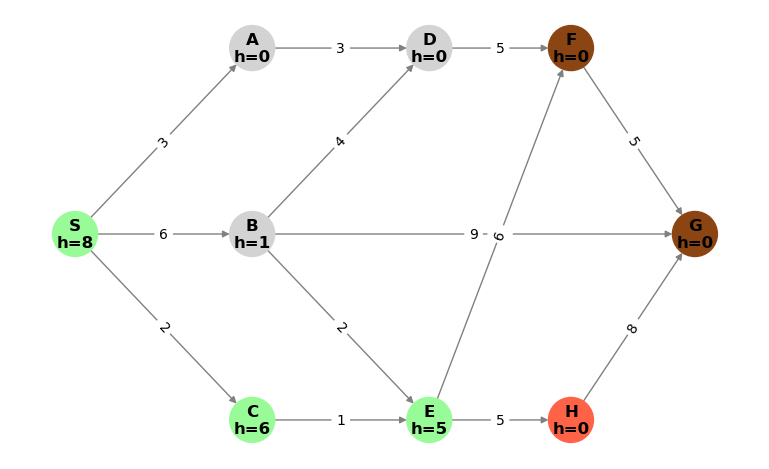

expansion order: ['S', 'A', 'D', 'B', 'C', 'E', 'H']
path: ['S', 'C', 'E', 'H']
total cost: 8


In [43]:
# Optional: manual step-by-step execution.
astar_step = run_search(
    ASTAR, CASE1, "A* CASE1", animate=True, step=True
)


In [44]:
# Uncomment for Case 2.
ucs2 = run_search(UCS, CASE2, "UCS CASE2")
gbfs2 = run_search(GBFS, CASE2, "GBFS CASE2")
astar2 = run_search(ASTAR, CASE2, "A* CASE2")


expansion order: ['A', 'Z', 'T', 'S', 'O', 'L', 'R', 'F', 'P', 'D', 'C', 'B']
path: ['A', 'S', 'R', 'P', 'B']
total cost: 418
expansion order: ['A', 'S', 'F', 'B']
path: ['A', 'S', 'F', 'B']
total cost: 450
expansion order: ['A', 'S', 'R', 'F', 'P', 'B']
path: ['A', 'S', 'R', 'P', 'B']
total cost: 418


## 10. Expected Results for Self-Check

### Case 1: `S` to `H`

| Algorithm | Expansion order | Returned path | Cost |
|---|---|---|---:|
| UCS | `S, C, A, E, B, D, H` | `S-C-E-H` | 8 |
| GBFS | `S, A, D, F, G, B, E, H` | `S-B-E-H` | 13 |
| A* | `S, A, D, B, C, E, H` | `S-C-E-H` | 8 |

### Case 2: `A` to `B`

| Algorithm | Expansion order | Returned path | Cost |
|---|---|---|---:|
| UCS | `A, Z, T, S, O, L, R, F, P, D, C, B` | `A-S-R-P-B` | 418 |
| GBFS | `A, S, F, B` | `A-S-F-B` | 450 |
| A* | `A, S, R, F, P, B` | `A-S-R-P-B` | 418 |

If only the final cost matches but the expansion order differs, check the alphabetical tie-break and the exact point at which you apply the goal test.
